## Week 1 - FIND-S Algorithm
###### Aim: Implement the FIND-S algorithm to find the most specific hypothesis from training examples stored in a CSV file.

In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn scipy jupyter


   ---------------- ----------------------- 2/5 [fqdn]
  Attempting uninstall: executing
   ---------------- ----------------------- 2/5 [fqdn]
    Found existing installation: executing 0.8.3
   ---------------- ----------------------- 2/5 [fqdn]
    Uninstalling executing-0.8.3:
   ---------------- ----------------------- 2/5 [fqdn]
      Successfully uninstalled executing-0.8.3
   ---------------- ----------------------- 2/5 [fqdn]
   ------------------------ --------------- 3/5 [executing]
   -------------------------------- ------- 4/5 [isoduration]
   ---------------------------------------- 5/5 [isoduration]



In [2]:

import pandas as pd

data = pd.read_csv("training.csv")

h = list(data.iloc[0, :-1])

for i in range(1, len(data)):
    if data.iloc[i, -1] == "Yes":
        for j in range(len(h)):
            if h[j] != data.iloc[i, j]:
                h[j] = "?"

print("Final Hypothesis:", h)


c:\Users\prash\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Final Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


Week 2: Candidate-Elimination Algorithm
Aim: Implement and demonstrate the Candidate-Elimination algorithm to find the set of all hypotheses consistent with the given training examples stored in a CSV file.

In [7]:

import pandas as pd

data = pd.read_csv("training.csv")

X = data.iloc[:, :-1].values
Y = data.iloc[:, -1].values

S = None
G = [['?' for _ in range(X.shape[1])]]

def covers(h, x):
    return all(a == '?' or a == b for a, b in zip(h, x))

for x, y in zip(X, Y):

    if y == "Yes":
        if S is None:
            S = list(x)
        else:
            for i in range(len(S)):
                if S[i] != x[i]:
                    S[i] = '?'

        G = [g for g in G if covers(g, x)]

    else:
        new_G = []

        for g in G:
            if covers(g, x):
                for i in range(len(g)):
                    if g[i] == '?' and S[i] != '?':
                        if S[i] != x[i]:
                            h = g.copy()
                            h[i] = S[i]
                            if covers(h, S):
                                new_G.append(h)
            else:
                new_G.append(g)

        G = new_G

print("Specific Boundary (S):", S)
print("General Boundary (G):")
for g in G:
    print(g)


Specific Boundary (S): ['Sunny', 'Warm', '?', 'Strong', '?', '?']
General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']


Week 3: 
Experiment 3(a): Entropy and Information Gain
Aim: Write a Python program to calculate Entropy and Information Gain.

In [8]:

import math

data = ['Yes', 'Yes', 'Yes', 'No', 'No']

def entropy(data):
    total = len(data)
    result = 0

    for value in set(data):
        p = data.count(value) / total
        result -= p * math.log2(p)

    return result

print("Entropy:", entropy(data))

# Information Gain
total_entropy = entropy(data)
left = ['Yes', 'Yes', 'Yes']
right = ['No', 'No']

gain = total_entropy - (
    len(left)/len(data) * entropy(left) +
    len(right)/len(data) * entropy(right)
)

print("Information Gain:", round(gain, 3))


Entropy: 0.9709505944546686
Information Gain: 0.971


Experiment 3(b): ID3 Decision Tree Algorithm
Aim: Implement the ID3 Decision Tree algorithm and classify a new sample.

In [9]:

import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

data = pd.DataFrame({
    'Outlook': ['Sunny', 'Sunny', 'Rainy', 'Rainy', 'Overcast'],
    'Temperature': ['Hot', 'Cool', 'Hot', 'Cool', 'Mild'],
    'Play': ['No', 'Yes', 'Yes', 'Yes', 'Yes']
})

X = pd.get_dummies(data.drop('Play', axis=1))
y = data['Play']

model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

print("Decision Tree:")
print(export_text(model, feature_names=list(X.columns)))

sample = pd.DataFrame([{
    'Outlook': 'Sunny',
    'Temperature': 'Cool'
}])

sample = pd.get_dummies(sample).reindex(columns=X.columns, fill_value=0)

print("Prediction:", model.predict(sample)[0])


Decision Tree:
|--- Temperature_Hot <= 0.50
|   |--- class: Yes
|--- Temperature_Hot >  0.50
|   |--- Outlook_Sunny <= 0.50
|   |   |--- class: Yes
|   |--- Outlook_Sunny >  0.50
|   |   |--- class: No

Prediction: Yes


week 4: Experiment 4(a): Perceptron Algorithm
Aim: Write a Python program to implement the Perceptron algorithm.


In [10]:

from sklearn.linear_model import Perceptron

X = [[0,0], [0,1], [1,0], [1,1]]
y = [0, 0, 0, 1]

model = Perceptron(max_iter=1000, eta0=0.1, random_state=0)
model.fit(X, y)

print("Predictions:", model.predict(X))
print("Actual:", y)


Predictions: [0 0 0 1]
Actual: [0, 0, 0, 1]


Experiment 4(b): Artificial Neural Network using Backpropagation
Aim: Build an Artificial Neural Network using the Backpropagation algorithm and test it using a suitable dataset.

In [11]:

from sklearn.neural_network import MLPClassifier

X = [[0,0], [0,1], [1,0], [1,1]]
y = [0, 1, 1, 0]

model = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation='tanh',
    solver='lbfgs',
    max_iter=5000,
    random_state=1
)

model.fit(X, y)

print("Actual Output:", y)
print("Predicted Output:", model.predict(X))


Actual Output: [0, 1, 1, 0]
Predicted Output: [0 1 1 0]


Week 5: Support Vector Machine (SVM)
Aim: Write a Python program to implement the SVM algorithm to classify the Iris dataset and print both correct and wrong predictions.

In [12]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train SVM model
model = SVC(kernel='linear')
model.fit(X_train, y_train)

# Predict output
pred = model.predict(X_test)

# Print predictions
correct = 0
wrong = 0

for actual, predicted in zip(y_test, pred):
    if actual == predicted:
        correct += 1
        print("Correct:", actual, predicted)
    else:
        wrong += 1
        print("Wrong:", actual, predicted)

print("\nCorrect Predictions:", correct)
print("Wrong Predictions:", wrong)
print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")


Correct: 1 1
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 0 0
Correct: 1 1
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 2 2
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 1 1
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 2 2
Correct: 0 0
Correct: 2 2
Correct: 0 0
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 1 1
Correct: 0 0
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 0 0
Correct: 0 0

Correct Predictions: 45
Wrong Predictions: 0
Accuracy: 100.0 %


Week 6: Locally Weighted Regression (LWR)
Aim: Implement the non-parametric Locally Weighted Regression algorithm to fit data points and draw a graph.

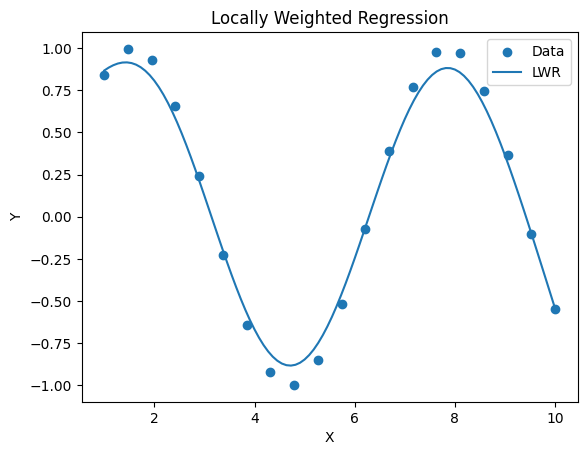

In [14]:
import numpy as np
import matplotlib.pyplot as plt

X = np.linspace(1, 10, 20)
y = np.sin(X)

X1 = np.c_[np.ones(len(X)), X]

def predict(x):
    w = np.exp(-((X-x)**2)/(2*0.5**2))
    W = np.diag(w)
    theta = np.linalg.pinv(X1.T @ W @ X1) @ X1.T @ W @ y
    return np.array([1, x]) @ theta

X_test = np.linspace(1, 10, 100)
y_pred = [predict(x) for x in X_test]

plt.scatter(X, y, label="Data")
plt.plot(X_test, y_pred, label="LWR")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Locally Weighted Regression")
plt.legend()
plt.show()

Week 7: Bayesian Network – Heart Disease Prediction
Aim: Write a Python program to construct a Bayesian Network using medical data and demonstrate the diagnosis of heart patients.

In [18]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE
from pgmpy.inference import VariableElimination

data = pd.DataFrame({
    'Age': ['Old','Old','Young','Young','Old','Young'],
    'ChestPain': ['Yes','No','Yes','No','Yes','No'],
    'HeartDisease': ['Yes','Yes','No','No','Yes','No']
})

model = DiscreteBayesianNetwork([
    ('Age','HeartDisease'),
    ('ChestPain','HeartDisease')
])

model.fit(data, estimator=DiscreteMLE(n_jobs=1))

result = VariableElimination(model).query(
    variables=['HeartDisease'],
    evidence={'Age':'Old', 'ChestPain':'Yes'}
)

print("Heart Disease Diagnosis:")
print(result)

Heart Disease Diagnosis:
+-------------------+---------------------+
| HeartDisease      |   phi(HeartDisease) |
+===================+=====================+
| HeartDisease(No)  |              0.0000 |
+-------------------+---------------------+
| HeartDisease(Yes) |              1.0000 |
+-------------------+---------------------+


Week 8: EM Algorithm and K-Means Clustering with Graph
Aim: Implement EM and K-Means algorithms on the same dataset, compare their clustering results, and visualize the clusters using graphs.

EM Clusters: 3
K-Means Clusters: 3


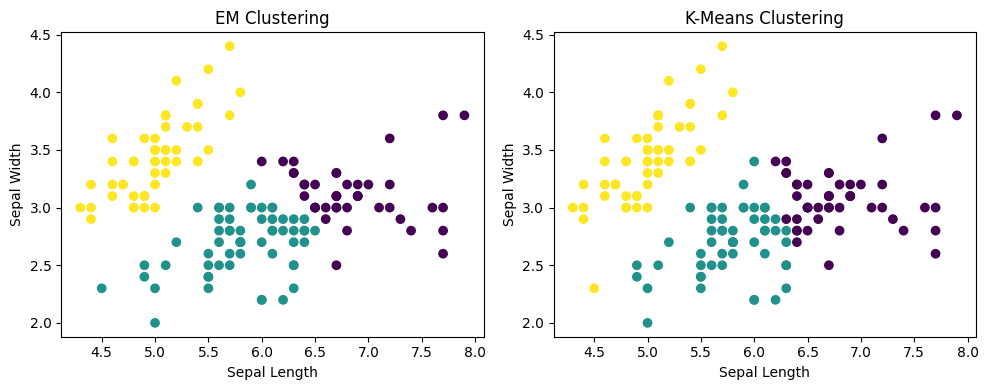

In [19]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans

# Load dataset
iris = load_iris()
X = iris.data[:, :2]

# EM Algorithm
em = GaussianMixture(n_components=3, random_state=42)
em_labels = em.fit_predict(X)

# K-Means Algorithm
km = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = km.fit_predict(X)

# Compare results
print("EM Clusters:", len(set(em_labels)))
print("K-Means Clusters:", len(set(km_labels)))

# Plot graphs
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=em_labels)
plt.title("EM Clustering")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=km_labels)
plt.title("K-Means Clustering")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.tight_layout()
plt.show()


Week 9: K-Nearest Neighbors (KNN) Algorithm
Aim: Write a Python program to implement the KNN algorithm to classify the Iris dataset and print both correct and wrong predictions.

In [20]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# KNN model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

# Predict
pred = model.predict(X_test)

# Print correct and wrong predictions
correct = 0
wrong = 0

for actual, predicted in zip(y_test, pred):
    if actual == predicted:
        correct += 1
        print("Correct:", actual, predicted)
    else:
        wrong += 1
        print("Wrong:", actual, predicted)

print("\nCorrect Predictions:", correct)
print("Wrong Predictions:", wrong)
print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")


Correct: 1 1
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 0 0
Correct: 1 1
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 2 2
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 1 1
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 2 2
Correct: 0 0
Correct: 2 2
Correct: 0 0
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 2 2
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 1 1
Correct: 0 0
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 0 0
Correct: 0 0
Correct: 0 0
Correct: 2 2
Correct: 1 1
Correct: 1 1
Correct: 0 0
Correct: 0 0

Correct Predictions: 45
Wrong Predictions: 0
Accuracy: 100.0 %
